# AllRecipes Data Analysis Project

## Imports

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle

## 1. Introduction

The data for this project comes from Allrecipes, a popular online platform where home cooks and food enthusiasts share and review recipes from around the world (Allrecipes, n.d.). The project comprises two datasets: allrecipes, a general collection of roughly 14,000 recipes spanning a wide range of dish types, cuisines, and a smaller collection of around 2,200 recipes organised by country of origin. For each recipe, the dataset captures a rich set of attributes, including the list of ingredients, nutritional information per serving (calories, fat, carbohydrates, and protein), the time needed to prepare and cook the dish, user ratings, and the number of reviews received (Mubia, 2025). One limitation to note is that review counts for highly popular recipes are truncated at the thousands, so these figures should be treated as approximate for widely-reviewed dishes (Mubia, 2025).

With such a large and varied collection of recipes, a practical question emerges: which recipes are genuinely worth attempting? A dish might earn glowing reviews yet require several hours of work, while another might be quick to make but nutritionally poor or too complex to replicate easily. This project explores the concept of "actionable" recipes, defined as those that are not only highly rated by the community but are also realistic for everyday home cooking across multiple dimensions, such as time, nutritional quality, and ingredient complexity. Our question of interest is therefore: Which recipes are the most "actionable" — highly rated, quick to prepare, nutritious and simple enough for everyday cooking? To investigate this, we merged the `allrecipes` dataset and the `cuisines` dataset, creating a larger set of recipes that provides a more reliable basis for identifying meaningful patterns. The variables most relevant to this analysis are the average user rating out of five stars (`avg_rating`), the total time recorded for each recipe in minutes (`total_time`), which includes preparation and cooking time but excludes passive waiting periods such as refrigeration and marination, the number of servings (`servings`), the derived nutrient density per serving (`nutrient_density_per_serving`), and the number of ingredients (`n_ingredient_lines`) derived from the ingredients column (`ingredients`). We additionally use the number of ratings received (`total_ratings`) as a credibility filter, retaining only recipes with at least 10 ratings to ensure that identified actionable recipes reflect genuine community consensus. By examining how these variables interact across thousands of recipes, we aim to surface patterns that reflect not just what tastes good, but what is realistically convenient, nutritious, and simple enough to be appealing for everyday cooking.

The data for this project comes from **Allrecipes**, a popular online platform where home cooks and food enthusiasts share and review recipes from around the world (**Allrecipes, n.d.**).

## Dataset Overview

This project uses **two datasets**:

- **`allrecipes`**: a general collection of roughly **14,000 recipes**, spanning a wide range of dish types and cuisines.
- **`cuisines`**: a smaller collection of around **2,200 recipes**, organised by country of origin.

For each recipe, the data includes:

- **Ingredients list**
- **Nutritional information per serving**:
  - calories
  - fat
  - carbohydrates
  - protein
- **Preparation and cooking time**
- **User ratings**
- **Number of reviews received**  
  (**Mubia, 2025**)

**Limitation:** Review counts for highly popular recipes are truncated at the thousands, so these values should be treated as approximate for widely reviewed dishes (**Mubia, 2025**).

## Research Motivation

With such a large and varied collection of recipes, a practical question emerges:  
**Which recipes are genuinely worth attempting?**

A recipe may be:

- highly rated but very time-consuming, or
- quick to prepare but nutritionally poor, or
- too complex to replicate easily in everyday cooking.

This project focuses on **“actionable” recipes**: recipes that are not only highly rated, but also realistic for everyday home cooking across multiple dimensions.

## Main Question

**Which recipes are the most “actionable” — highly rated, quick to prepare, nutritious, and simple enough for everyday cooking?**

## Approach

To investigate this question:

- We merged the **`allrecipes`** and **`cuisines`** datasets.
- This created a larger combined dataset, providing a more reliable basis for identifying meaningful patterns.

## Key Variables Used

The most relevant variables are:

- **`avg_rating`**: average user rating out of five stars
- **`total_time`**: total time in minutes (includes preparation and cooking, excludes passive waiting periods such as refrigeration and marination)
- **`servings`**
- **`nutrient_density_per_serving`** (derived)
- **`n_ingredient_lines`**: number of ingredients, derived from **`ingredients`**
- **`total_ratings`**: used as a credibility filter

## Credibility Filter

To ensure meaningful consensus:

- Only recipes with **at least 10 ratings** were retained.

## Analytical Goal

By examining how these variables interact across thousands of recipes, this project aims to identify patterns that reflect not only what tastes good, but also what is realistically:

- **convenient**
- **nutritious**
- **simple enough** for everyday cooking.

## 2. Data Cleaning and Summary

### 2.1 Imports

In [2]:
import pandas as pd
import numpy as np
import re
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

### 2.1 Loading the datasets

In [20]:
url_recipes = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/all_recipes.csv'
url_cuisines = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/cuisines.csv'

# Turn links into DataFrames
df_recipes = pd.read_csv(url_recipes)
df_cuisines = pd.read_csv(url_cuisines)

In [4]:
df_recipes.head()

,name,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,total_ratings,reviews,prep_time,cook_time,total_time,servings
0,Chewy Whole Wheat Peanut Butter Brownies,https://www.allrecipes.com/recipe/140717/chewy...,DMOMMY,2020-06-18,"⅓ cup margarine, softened, ⅔ cup white sugar, ...",222.0,13.0,24.0,6.0,4.4,47.0,36.0,20,35,55,16.0
1,Pumpkin Pie Eggnog,https://www.allrecipes.com/recipe/269204/pumpk...,Bobbie Susan,2022-09-26,"12 egg yolks, 2 cups heavy whipping cream, ½ ...",477.0,31.0,43.0,8.0,5.0,1.0,1.0,10,5,495,8.0
2,Eggs Poached in Tomato Sauce,https://www.allrecipes.com/recipe/238054/eggs-...,Bren,2018-06-08,"2 tablespoons olive oil, or to taste, ½ onion...",354.0,18.0,32.0,20.0,4.8,4.0,4.0,10,75,85,4.0
3,Minestrone Casserole,https://www.allrecipes.com/minestrone-casserol...,Sarah Brekke,2025-03-03,4 cups dried mafalda pasta (mini lasagna noodl...,356.0,9.0,53.0,19.0,4.3,14.0,13.0,20,40,60,8.0
4,Yummy Stuffed Peppers,https://www.allrecipes.com/recipe/241937/yummy...,Procrastigirl,2024-12-11,"4 green bell peppers, halved lengthwise and se...",366.0,22.0,23.0,19.0,4.7,84.0,67.0,30,95,125,8.0


In [5]:
df_cuisines.head()

,name,country,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,total_ratings,reviews,prep_time,cook_time,total_time,servings
0,Saganaki (Flaming Greek Cheese),Greek,https://www.allrecipes.com/recipe/263750/flami...,John Mitzewich,2024-02-07,"1 (4 ounce) package kasseri cheese, 1 tablespo...",391.0,25.0,15.0,16.0,4.8,25.0,22.0,10,5,15,2.0
1,Coney Island Knishes,Jewish,https://www.allrecipes.com/recipe/272334/coney...,John Mitzewich,2024-11-26,"2 ¾ cups all-purpose flour, or more as needed,...",301.0,17.0,31.0,7.0,4.6,10.0,9.0,30,75,180,16.0
2,Diana's Hawaiian Bread Rolls,Australian and New Zealander,https://www.allrecipes.com/recipe/22797/dianas...,CHIPPENDALE,2022-07-14,1 ½ cups warm water (110 degrees F/45 degrees ...,64.0,3.0,9.0,1.0,4.3,126.0,104.0,20,15,180,12.0
3,Chilean Pebre,Chilean,https://www.allrecipes.com/recipe/273763/chile...,Heidi,2025-01-31,"½ cup chopped cilantro, ¼ cup olive oil, ¼ cup...",106.0,9.0,7.0,1.0,5.0,1.0,1.0,10,0,10,6.0
4,Tex-Mex Sheet Cake,Tex-Mex,https://www.allrecipes.com/recipe/22388/tex-me...,Ann,2025-02-18,"2 cups all-purpose flour, 1 ½ cups brown sugar...",449.0,23.0,58.0,7.0,3.8,13.0,11.0,30,15,45,15.0


### 2.2 Data cleaning

## Data Cleaning Steps

- **Merge datasets**  
  Use an **outer join** on `url` to combine `df_recipes` with cuisine labels from `df_cuisines` (`country` renamed to `cuisine`).

- **Standardize numeric columns**  
  Convert key columns (`calories`, `fat`, `carbs`, `protein`, `avg_rating`, `total_ratings`, `reviews`, `prep_time`, `cook_time`, `total_time`, `servings`) to numeric with `errors='coerce'`.

- **Handle invalid numeric values**  
  Any non-numeric values become `NaN` during conversion.

- **Drop rows missing essential fields**  
  Remove rows with missing values in: `name`, `avg_rating`, `ingredients`, `prep_time`, `cook_time`, `total_time`.

- **Filter invalid duration records**  
  Keep only rows where `total_time > 0` (remove zero-time recipes).


  Additionally, we check after each step whether rows were lost or gained using a simple audit table.

In [22]:
import pandas as pd

# Start fresh from raw merge inputs
df_step = pd.merge(
    df_recipes,
    df_cuisines[['url', 'country']].rename(columns={'country': 'cuisine'}),
    on='url',
    how='outer'
)

audit = []
def log_step(step_name, frame):
    audit.append({
        "step": step_name,
        "rows": len(frame)
    })

# Step 0: after merge
log_step("0) After outer merge", df_step)

# Step 1: numeric conversion (row count usually unchanged)
num_cols = [
    "calories", "fat", "carbs", "protein", "avg_rating",
    "total_ratings", "reviews", "prep_time", "cook_time",
    "total_time", "servings"
]
for col in num_cols:
    df_step[col] = pd.to_numeric(df_step[col], errors="coerce")
log_step("1) After numeric conversion", df_step)

# Step 2: drop missing essentials
df_step = df_step.dropna(subset=[
    "name", "avg_rating", "ingredients", "prep_time", "cook_time", "total_time"
])
log_step("2) After dropna essentials", df_step)

# Step 3: remove total_time <= 0
df_step = df_step[df_step["total_time"] > 0]
log_step("3) After total_time > 0 filter", df_step)

# Build summary table
summary = pd.DataFrame(audit)
summary["change_vs_prev"] = summary["rows"].diff().fillna(0).astype(int)
summary["pct_change_vs_prev"] = (
    summary["rows"].pct_change().fillna(0) * 100
).round(2)

# Optional: clearer +/- labels
summary["change_label"] = summary["change_vs_prev"].apply(
    lambda x: f"+{x}" if x > 0 else str(x)
)

summary

,step,rows,change_vs_prev,pct_change_vs_prev,change_label
0,0) After outer merge,15589,0,0.0,0
1,1) After numeric conversion,15589,0,0.0,0
2,2) After dropna essentials,13454,-2135,-13.7,-2135
3,3) After total_time > 0 filter,13104,-350,-2.6,-350


### 2.3 Some feature engineering for summary statistics

## Ingredient Count Derivation (`n_ingredient_lines`)

This step creates a derived variable, **`n_ingredient_lines`**, by estimating the number of distinct ingredients in each recipe from the `ingredients` text field.

### Function: `count_ingredients(s)`

- Takes one recipe’s ingredient string as input.
- Returns the number of cleaned, distinct ingredient entries.

### Logic Used

- **Handle missing or empty input**
  - If `s` is null or blank, return `0`.

- **Define noise words**
  - A `noise_list` is used to remove non-ingredient terms such as:
    - units (e.g., `cup`, `teaspoon`, `gram`)
    - preparation words (e.g., `chopped`, `minced`, `diced`)
    - generic modifiers (e.g., `large`, `small`, `optional`)

- **Split ingredient text**
  - Ingredients are split by comma into raw segments.

- **Clean each segment**
  - Convert to lowercase.
  - Remove digits.
  - Replace punctuation (`. , ( ) !`) with spaces.
  - Split into words.
  - Remove words found in `noise_list`.
  - Rejoin remaining words into a cleaned ingredient name.

- **Keep meaningful entries only**
  - Only cleaned names with length greater than 2 are kept.
  - Valid names are added to a `set` to keep only distinct items.

- **Return count**
  - Return the size of the distinct ingredient set.

### Output Column

- The function is applied to `df['ingredients']`.
- Result is stored in:

- **`df['n_ingredient_lines']`**

### Purpose in Analysis

This creates a practical proxy for **ingredient complexity**:
- higher `n_ingredient_lines` → likely more complex recipe
- lower `n_ingredient_lines` → likely simpler, more actionable recipe

In [8]:
# Count ingredient lines
def count_ingredients(s):
    if pd.isna(s) or str(s).strip() == "":
        return 0
    
    # Cleaning Noise (Units, preparation steps and common adjectives)
    noise_list = ["cup", "cups", "tablespoon", "tablespoons", "teaspoon", "teaspoons", 
        "pound", "pounds", "ounce", "ounces", "gram", "grams", "ml", "beaten", "divided", "fresh"
        "chopped", "minced", "sliced", "diced", "crushed", "mashed", "clove", "cloves", "pinch", "ripe"
        "dried", "fresh", "to", "taste", "as", "needed", "large", "small", "medium", "all-purpose", 
        "packed", "shredded", "optional", "more", "less", "than", "or", 'can', 'packaged'
    ]
    
    # Split by comma (line separation)
    raw_lines = str(s).split(",")
    distinct_ingredients = set()
    
    for line in raw_lines:
        clean = line.lower()                                            # lowercase

        clean = "".join([char for char in clean if not char.isdigit()]) # Remove numbers

        for char in ".,()!":                                            # Replace punctuation with spaces 
            clean = clean.replace(char, " ")

        words = clean.split()                                           # Remove noise words
        filtered_words = [word for word in words if word not in noise_list]
        clean_name = " ".join(filtered_words).strip()
        
        # Only add if there is meaningful text left (ignores words like "a" and "or" or empty strings)
        if len(clean_name) > 2:
            distinct_ingredients.add(clean_name)
            
    return len(distinct_ingredients)

df['n_ingredient_lines'] = df['ingredients'].apply(count_ingredients)

### Nutritional Value Metric

We measure nutritional quality using **nutrient density**, which captures nutrients relative to calories.

**Formula:**

`nutrient_density = ((protein * 4) + (fat * 9)) / calories`

To adjust for portion size, we then compute:

`nutrient_density_per_serving = nutrient_density / servings`

This gives a normalized measure of nutritional value per serving.

In [9]:
df['nutrient_density'] = ((df['protein'] * 4) + (df['fat'] * 9)) / df['calories']

# Find nutrient density per serving
df['nutrient_density_per_serving'] = df['nutrient_density'] / df['servings']

### Actionability Scoring

In this step, we keep only recipes with at least **10 ratings** (to ensure reliability), then compute standardized scores to compare recipes fairly.

- **`z_rating`**: how highly a recipe is rated compared with others  
- **`z_ingredients`**: how complex a recipe is based on ingredient count  
- **`z_log_time`**: how time-consuming a recipe is (after log-transforming total time to reduce skew)

Using these, we create:

- **`complexity_score = z_rating - z_ingredients`**  
  (higher when a recipe is highly rated and uses fewer ingredients)

- **`action_score = z_rating - z_log_time`**  
  (higher when a recipe is highly rated and quicker to make)

- **`ultimate_score = z_rating - (z_log_time + z_ingredients)`**  
  (higher when a recipe is highly rated, quick, and simple)

In [10]:
df['log_total_time'] = np.log1p(df['total_time'])  # log-transform heavily skewed data
df_filtered = df[df['total_ratings'] >= 10].copy() # Filter for reliable averages

# Actionable Score
df_filtered['z_rating'] = stats.zscore(df_filtered['avg_rating'])

df_filtered['z_ingredients'] = stats.zscore(df_filtered['n_ingredient_lines'])
df_filtered['complexity_score'] = df_filtered['z_rating'] - df_filtered['z_ingredients']

df_filtered['z_log_time'] = stats.zscore(np.log1p(df_filtered['total_time']))
df_filtered['action_score'] = df_filtered['z_rating'] - df_filtered['z_log_time']

df_filtered['ultimate_score'] = df_filtered['z_rating'] - (df_filtered['z_log_time'] + df_filtered['z_ingredients'])

In [11]:
df_filtered.columns

Index(['name', 'url', 'author', 'date_published', 'ingredients', 'calories',
       'fat', 'carbs', 'protein', 'avg_rating', 'total_ratings', 'reviews',
       'prep_time', 'cook_time', 'total_time', 'servings', 'cuisine',
       'n_ingredient_lines', 'nutrient_density',
       'nutrient_density_per_serving', 'log_total_time', 'z_rating',
       'z_ingredients', 'complexity_score', 'z_log_time', 'action_score',
       'ultimate_score'],
      dtype='object')

### 2.4 Key summary statistics

## Key Distribution Insights and Modeling Decisions

In [12]:
print("--- General Dataset Shape ---")
print(f"Total recipes after cleaning: {len(df):,}")
print(f"Recipes with cuisine tags: {df['cuisine'].notna().sum():,}")

print("\n" + "="*100)

print("\n--- Key Factors Summary ---")
rating_stats = df[['avg_rating', 'total_ratings', 'total_time', 'nutrient_density_per_serving', 'servings', 'n_ingredient_lines']].describe().loc[['min', '25%', 'mean', '50%', '75%', 'max']]
display(rating_stats)

--- General Dataset Shape ---
Total recipes after cleaning: 13,104
Recipes with cuisine tags: 1,001


--- Key Factors Summary ---


,avg_rating,total_ratings,total_time,nutrient_density_per_serving,servings,n_ingredient_lines
min,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
25%,4.400000,5.000000,30.000000,0.039969,4.250000,8.000000
mean,4.531219,102.082036,149.599435,0.102260,11.058729,11.123932
50%,4.600000,26.000000,55.000000,0.077519,8.000000,10.000000
75%,4.800000,111.000000,105.000000,0.131356,12.000000,14.000000
max,5.000000,997.000000,60485.000000,1.000000,300.000000,38.000000


Interpretation

The distribution of `avg_rating` is concentrated at high values (mean = **4.53**, median = **4.60**), indicating a strong positivity bias in ratings. Since the median is slightly higher than the mean, the distribution is mildly negatively skewed. In this context, a rating of **4.0** is below the dataset average, so stronger “actionable” candidates are expected to be above the median rating.

For `total_ratings`, the mean (**102**) is much higher than the median (**26**), with a maximum of **997**, indicating a strongly right-skewed distribution driven by highly reviewed recipes. To improve reliability in downstream scoring, we apply a credibility filter and retain only recipes with at least **10 ratings**.

`total_time` shows a similar pattern (mean = **150**, median = **55**), which also indicates strong right skew. To reduce skewness and make comparisons more stable, we use a log-transformed variable, **`log_total_time`**.#### Individual data statistics

In [13]:
print(df_filtered['servings'].value_counts())

servings
8.0      1697
6.0      1518
4.0      1454
12.0      986
10.0      450
         ... 
26.0        1
134.0       1
27.0        1
22.0        1
49.0        1
Name: count, Length: 63, dtype: int64


The most frequent serving sizes in the dataset are **4, 6, 8, and 12**, which align with typical home-cooking portions. Beyond these values, frequencies decline sharply; serving sizes such as **26, 49, and 134** appear only once, suggesting they are rare outliers.

To simplify interpretation, recipes are grouped into three serving-size categories:

- **Small:** 1-4 servings *(individual or couple meals)*
- **Medium:** 5-8 servings *(family-sized meals)*
- **Large:** 9+ servings *(batch cooking or gatherings)*

#### Interconnected data statistics

In [14]:
# Do faster recipes get more reviews?
print("\n--- Total Reviews by Time Category ---")
df['time_quartile'] = pd.qcut(df['total_time'], 4, labels=['Very Fast', 'Fast', 'Medium', 'Slow'])
engagement = df.groupby('time_quartile', observed=True)['total_ratings'].agg(['mean', 'std'])
display(engagement)


--- Total Reviews by Time Category ---


,mean,std
time_quartile,,
Very Fast,100.252870,172.070778
Fast,103.902074,176.484700
Medium,110.125816,181.118917
Slow,93.493643,162.234260


An additional insight is that the **third time quartile (medium-time recipes)** has the **highest mean number of ratings** (**110**), while the **slowest quartile** has the **lowest** (**93**).

This suggests that **time meaningfully influences user engagement**. Recipes with moderate preparation time appear to attract the most interaction, followed by fast and very fast recipes, whereas the slowest recipes receive the least engagement.

Overall, this supports our guiding question: **total recipe time affects users’ willingness to try and rate recipes**, and therefore plays an important role in identifying actionable recipes.

In [15]:
# Is there a correlation between Time and Rating?
corr_time_rating = df_filtered[['total_time', 'avg_rating']].corr().iloc[0,1]
print(f"\nPearson Correlation between Total Time and Average Rating: {corr_time_rating:.4f}")

# What are the fastest recipes with high ratings?
print("\n--- Top 5 Fastest High-Rated Recipes (High Rating, Low Time) ---")
display(df_filtered.sort_values('action_score', ascending=False)[['name', 'total_time', 'avg_rating', 'n_ingredient_lines', 'action_score']].head(5))

print("\n" + "="*100)

# Is there a correlation between Number of Ingredients and Rating?
corr_ingredients_rating = df_filtered[['n_ingredient_lines', 'avg_rating']].corr().iloc[0,1]
print(f"\nPearson Correlation between Number of Ingredients and Average Rating: {corr_ingredients_rating:.4f}")

# What are the low-ingredient recipes with high ratings?
print("\n--- Top 5: Simplest High-Rated Recipes (Low Ingredients) ---")
display(df_filtered.sort_values('complexity_score', ascending=False)
        [['name', 'avg_rating', 'n_ingredient_lines', 'complexity_score']].head(5))

print("\n" + "="*100)

# Is there a correlation between Time and Number of Ingredients?
complexity_corr = df_filtered[['total_time', 'n_ingredient_lines']].corr().iloc[0,1]
print(f"\nCorrelation between Total Time and Number of Ingredients: {complexity_corr:.4f}")

# What are the fastest, low-ingredient recipes with high ratings?
print("\n--- Top 5: Simplest and Fastest High-Rated Recipes (High Rating, Low Time, Low Ingredients) ---")
display(df_filtered.sort_values('ultimate_score', ascending=False)
        [['name', 'avg_rating', 'total_time', 'n_ingredient_lines', 'ultimate_score']].head(5))


Pearson Correlation between Total Time and Average Rating: 0.0058

--- Top 5 Fastest High-Rated Recipes (High Rating, Low Time) ---


,name,total_time,avg_rating,n_ingredient_lines,action_score
8077,Christmas Poinsettia Punch,5.0,5.0,6,4.022274
1761,Peach Cosmo,5.0,5.0,5,4.022274
7213,Prickly Pear Margarita,5.0,5.0,6,4.022274
2227,Simple Cranberry Spinach Salad,5.0,5.0,5,4.022274
4417,Pumpkin Pie Spice I,1.0,4.7,4,3.979555




Pearson Correlation between Number of Ingredients and Average Rating: 0.0973

--- Top 5: Simplest High-Rated Recipes (Low Ingredients) ---


,name,avg_rating,n_ingredient_lines,complexity_score
10041,Baked Corn Tortilla Strips for Mexican Soups,5.0,2,3.654063
12139,Microwave Spaghetti Squash,5.0,2,3.654063
9867,Low-Carb Keto Cheese Taco Shells,4.9,1,3.504139
9514,Homemade Clotted Cream,4.9,1,3.504139
11253,3-Ingredient Whipped Cream,5.0,3,3.432800




Correlation between Total Time and Number of Ingredients: -0.0086

--- Top 5: Simplest and Fastest High-Rated Recipes (High Rating, Low Time, Low Ingredients) ---


,name,avg_rating,total_time,n_ingredient_lines,ultimate_score
14909,Classic White Wine Spritzer,4.9,5.0,2,5.589619
4417,Pumpkin Pie Spice I,4.7,1.0,4,5.475561
5753,S'mores,4.9,5.0,3,5.368356
8445,Colored Sugar,4.9,5.0,3,5.368356
5676,Classic Ham Glaze,4.9,5.0,3,5.368356


In investigating the relationship between rating with time and number of ingredients, there is **lack of correlation** between time, ingredients and ratings (r = 0.0058 between time and rating, r = 0.1028 between ingredients and rating, and r = -0.0091 between ingredients and time). This shows that there is no correlation between ratings with time and with ingredients, making the search for actionable recipes valid. 

The most actionable recipe based on time and both time and number of ingredients are **drinks** and the top 5 actionable recipes is found to contain many drinks. However, the most actionable recipe based on the number of ingredients is food and the top 5 contains mainly food, soup and creams. This suggests that for high ratings, the types of recipes for lowest time and lowest number of ingredients differ slightly. However, the most actionable recipes are often **components (creams) or drinks**. This suggests that recipes that take less time are more likely recipes for drinks. This validates our finding that recipes with medium time have the highest mean total reviews as the medium time category may have more recipes for food that take less time. Hence, current users may be more attracted to these recipes.

#### Initial findings for actionable recipes

In [16]:
# Define actionable recipes as as the top 10% of ultimate_score
top_threshold = df_filtered['ultimate_score'].quantile(0.9)
df_filtered['is_top_actionable'] = df_filtered['ultimate_score'] >= top_threshold

print("\n" + "="*100)

# Do actionable recipes have higher nutritional value(nutrient_density_per_serving))?
print("\n--- Nutritional Comparison: Actionable vs. Others ---")
nutritional_comp = df_filtered.groupby('is_top_actionable')[['nutrient_density_per_serving']].median()
display(nutritional_comp)



--- Nutritional Comparison: Actionable vs. Others ---


,nutrient_density_per_serving
is_top_actionable,
False,0.075300
True,0.091116


The fact that actionable recipes has a **higher nutrient_density_per_serving** is a key insight. It suggests that actionable recipes are **fast, lighter and potentially healthier**. However, this may also be due to the fact that the most actionable recipes are mostly drinks that would usually have less calories, fat and protein compared to food. 

## 3. Visualisation

### 3.1 Scatterplot

This scatterplot uses three variables: total cooking time in minutes (`total_time`), average user rating out of five stars (`avg_rating`), and number of servings (`servings`), which is binned into three groups — small (1–4 servings), medium (5–8 servings), and large (9+ servings) (`serving_group`). Each point in the scatter plot represents an individual recipe.

A scatter plot is ideal here because our core question asks about the relationship between two continuous variables, time and rating, and a scatter plot is the most direct way to visualise how these two dimensions interact across thousands of recipes simultaneously. It allows the reader to immediately identify where the actionable zone lies: recipes that cluster in the upper-left region of the plot (low total time, high rating) are the most actionable. 

Faceting by serving size adds a meaningful third dimension without cluttering a single plot. It allows us to investigate whether the actionable zone shifts depending on the scale of the recipe. For instance, whether large-batch recipes tend to require more time and thus are less likely to be actionable, or whether smaller single-serving recipes dominate the sweet spot. The bins were determined based on the observed distribution of serving sizes in the data. This faceted design keeps each individual panel clean and readable while enabling direct visual comparison across serving size groups.

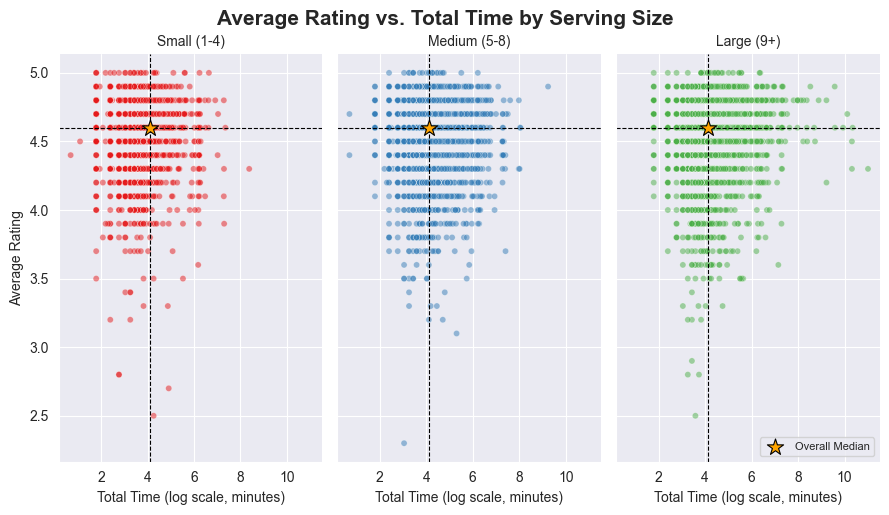

In [17]:
# Define serving group bins
serving_bins = [0, 4, 8, np.inf]
serving_labels = ['Small (1-4)', 'Medium (5-8)', 'Large (9+)']
df_filtered['serving_group'] = pd.cut(df_filtered['servings'], bins=serving_bins, labels=serving_labels)

# Overall median reference point
median_time = df_filtered['log_total_time'].median()
median_rating = df_filtered['avg_rating'].median()

# Set style and extract Set1 colours
sns.set_style('darkgrid')
panel_colours = sns.color_palette('Set1', 3)

# Plot the Scatterplot
g = sns.relplot(
    data=df_filtered,
    kind='scatter',
    x='log_total_time',
    y='avg_rating',
    col='serving_group',
    hue='serving_group',
    palette='Set1',
    alpha=0.5,
    s=20,
    height=5,
    aspect=0.6,
    legend=False
)

# Add quadrant lines and median marker per panel
for ax in g.axes.flat:
    ax.axhline(y=median_rating, color='black', linestyle='--', linewidth=0.8)
    ax.axvline(x=median_time, color='black', linestyle='--', linewidth=0.8)
    ax.scatter(median_time, median_rating,
               color='orange', s=150, zorder=5,
               edgecolors='black', linewidth=0.8,
               marker='*', label='Overall Median')

# Add legend for the median marker
g.axes.flat[-1].legend(loc='lower right', fontsize=8)
g.set_axis_labels('Total Time (log scale, minutes)', 'Average Rating')
g.set_titles(col_template='{col_name}')
g.figure.suptitle('Average Rating vs. Total Time by Serving Size',
                   fontsize=15, fontweight='bold', y=1.02)

plt.show()

### 3.2 Bar Chart

To investigate actionable recipes, we are questioning **whether faster recipes are able to maintain both strong user ratings and nutritional quality** and to do so we have constructed a **faceted stacked bar chart**. 

This bar chart simultaneously examines the relationship between **rating, cooking time and nutrient density**. 

The key variables used in this visualisation are:

`total_time`: which is grouped into discrete time bins using `pd.cut()` to represent different levels of effort put into the recipes. 

`avg-rating`: these are similarly grouped into rating intervals to capture how user satisfaction is distributed. 

`nutrient_density_per_serving`: it is categorized into low, medium, high nutrient density groups to reflect the nutritional quality of each recipe. 

These transformations allow us to anayse patterns across meaningful categories, thereby making comparisons more interpretable. 

For each time bin (5 time bins), a contingency table is constructed between the different rating groups and nutrient density groups. 
Row wise normalisation has been applied. 

This normalisation allows us to represent each bar as proportions rather than raw counts, allowing easy comparison of how nutrient density changes across rating levels within each time category.  Each bar corresponds to a rating group and is divided into segments representing the proportion of recipes that are “low”, “medium” or “high” in nutrient density. 

The visualisation is faceted across multiple time bins using many subplots. This design was chosen to **isolate the relationship between rating and nutritional quality within each level of time commitment**, rather than aggregating across all recipes. By doing so we can assess whether quicker recipes exhibit different patterns compared to more intensive ones. 

This type of visualisation helps us understand the trade-offs and composition (**whether highly rated recipes are ALSO nutritionally strong and less time consuming**), a stacked proportional bar chart allows us to clearly observe how the makeup of nutrient density varies across rating levels. Faceting allows us to compare these patterns across different levels of effort (time), which is pivotal to identifying “actionable” recipes. 

Hence, from this visualisation we can assess whether highly rated recipes in shorter time categories are dominated by high-nutrient density options, or whether faster recipes tend to sacrifice nutritional quality. 

**If we observe that high-rating groups within shorter time bins still contain a substantial portion of medium-high nutrient density recipes, this suggests that there is a certain subsector of recipes which are both efficient to prepare and desirable in terms of both taste and nutrition.**

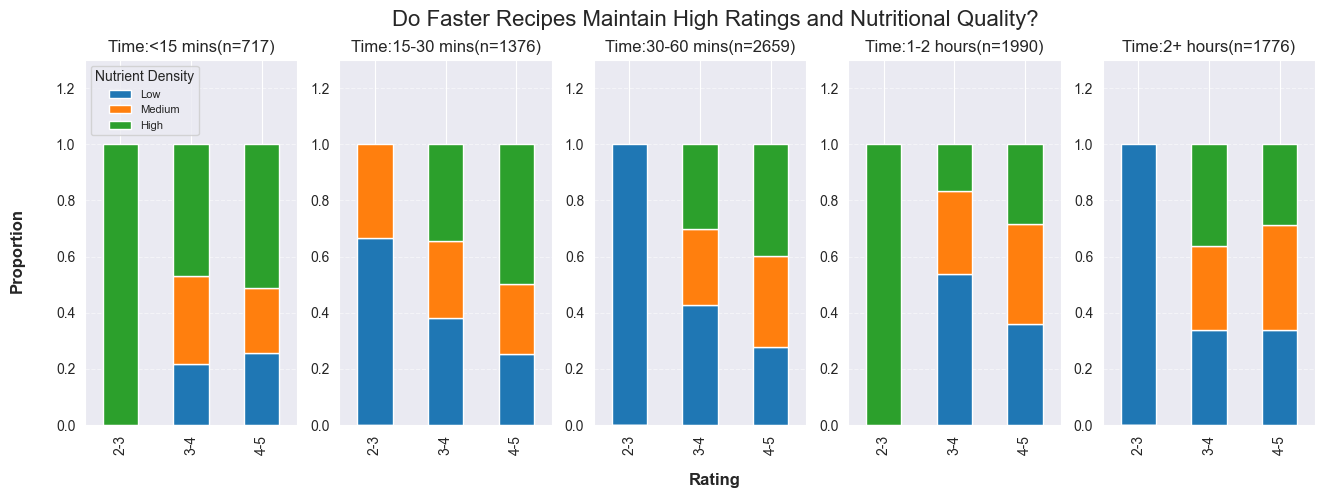

In [18]:
# Create time bins
df_filtered["time_bin"] = pd.cut(
   df_filtered["total_time"],                  
   bins=[0, 15, 30, 60, 120, np.inf],  
   labels=['<15 mins', '15-30 mins', '30-60 mins', '1-2 hours', '2+ hours']
)
# Create rating bins
df_filtered["rating_bin"] = pd.cut(
   df_filtered["avg_rating"],                 
   bins=[0, 2, 3, 4, 5],         
   labels=["0-2", "2-3", "3-4", "4-5"],
   ordered=True
)
# Create nutrient density per serving grps
df_filtered["nutrient_density_group"] = pd.cut(
   df_filtered["nutrient_density_per_serving"],                  
   bins=[0, 0.05, 0.1, 10],       
   labels=["Low", "Medium", "High"]
)
# Removal of missing values in the time bins
time_categories = df_filtered["time_bin"].cat.categories


fig, axes = plt.subplots(1, len(time_categories), figsize=(15, 5))
fig.suptitle("Do Faster Recipes Maintain High Ratings and Nutritional Quality?", fontsize=16)


# Loop over all time bins
for i in range(len(time_categories)):
   time_cat = time_categories[i]      
   subplot = axes[i]                      
   subset = df_filtered[df_filtered["time_bin"] == time_cat]
   contingency_table = pd.crosstab( subset["rating_bin"],subset["nutrient_density_group"], normalize="index")
   contingency_table.plot( kind="bar",stacked=True,ax=subplot)
   subplot.set(title="Time:" + str(time_cat) + "(n=" + str(len(subset))+")", xlabel="", ylabel="")
   subplot.grid(axis="y", linestyle="--", alpha=0.5)
   subplot.set_ylim(0, 1.30)
   if i > 0:
       subplot.legend().remove()
   else:
       subplot.legend(title="Nutrient Density", loc="upper left", fontsize=8)
plt.subplots_adjust(left=0.08, bottom=0.15)
# Adding shared axis labels (so each one doesn't have)
fig.text(0.5, 0.03, 'Rating', ha='center', fontsize=12, fontweight='bold')
fig.text(0.03, 0.5, 'Proportion', va='center', rotation='vertical', fontsize=12, fontweight='bold')


plt.show()

### 3.3 Heatmap

This heatmap uses three variables:
1. Total cooking time in minutes (total_time)
2. Number of ingredients (n_ingredient_lines)
3. Average user rating out of five stars (avg_rating)

(1) and (2) are binned into categorical groups. Each cell in the matrix represents the mean rating of all recipes that fall into that specific time and complexity combination.

A heatmap is ideal here because it allows us to test the intersection of two different types of effort (time and complexity) against our target metric simultaneously. While a scatter plot excels at showing overall distribution, a heatmap aggregates the data into a clean, easy-to-read matrix. By using colour intensity to represent the average rating, it shows macro-level trends that might otherwise be lost in the noise, allowing the reader to instantly evaluate how different levels of cooking effort impact community satisfaction.

Adding the explicit red boundary around the low-time, low-ingredient quadrants provides a strong visual anchor, strictly defining what constitutes an accessible recipe. Furthermore, incorporating a sample size check adds statistical rigour. By flagging cells with fewer than 30 recipes with an asterisk, we ensure the reader can distinguish between a genuinely reliable trend and a highly rated, but statistically insignificant, niche.

/var/folders/c8/2p8mt99n0qd0579_vwy252380000gn/T/ipykernel_46803/3913212085.py:9: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = df_filtered.pivot_table(
/var/folders/c8/2p8mt99n0qd0579_vwy252380000gn/T/ipykernel_46803/3913212085.py:15: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  count_data = df_filtered.pivot_table(


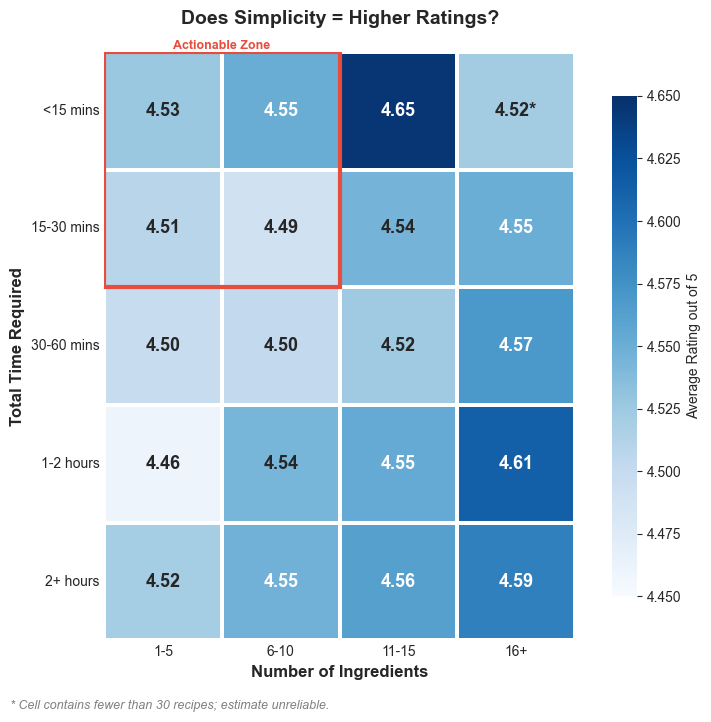

In [19]:
# Create 'total_time' and 'n_ingredient_lines' buckets
time_bins = [0, 15, 30, 60, 120, np.inf]
time_labels = ['<15 mins', '15-30 mins', '30-60 mins', '1-2 hours', '2+ hours']
df_filtered['time_bucket'] = pd.cut(df_filtered['total_time'], bins = time_bins, labels = time_labels)
ingredient_bins = [0, 5, 10, 15, np.inf]
ingredient_labels = ['1-5', '6-10', '11-15', '16+']
df_filtered['ingredient_bucket'] = pd.cut(df_filtered['n_ingredient_lines'], bins = ingredient_bins, labels = ingredient_labels)

heatmap_data = df_filtered.pivot_table(
    index = 'time_bucket',
    columns = 'ingredient_bucket',
    values = 'avg_rating',
    aggfunc = 'mean'
)
count_data = df_filtered.pivot_table(
    index = 'time_bucket',
    columns = 'ingredient_bucket',
    values = 'avg_rating',
    aggfunc = 'count'
)

fig, ax = plt.subplots(figsize = (8, 7))
annot_labels = pd.DataFrame(index = heatmap_data.index, columns = heatmap_data.columns)
for row in heatmap_data.index:
    for col in heatmap_data.columns:
        mean_val = heatmap_data.loc[row, col]
        n_val = int(count_data.loc[row, col])
        if n_val < 30:
            annot_labels.loc[row, col] = f"{mean_val:.2f}*"
        else:
            annot_labels.loc[row, col] = f"{mean_val:.2f}"

sns.heatmap(
    heatmap_data,
    annot = annot_labels,
    fmt = '',
    cmap = 'Blues',
    vmin = 4.45,
    vmax = 4.65,
    square = True,
    linewidths = 1.5,
    linecolor = 'white',
    annot_kws = {"size": 13, "weight": "bold"},
    cbar_kws = {'label': 'Average Rating out of 5', 'shrink': 0.85},
    ax = ax
)

# Highlight & label the actionable areas
ax.add_patch(Rectangle(
    (0, 0), 2, 2,          
    fill = False,
    edgecolor = '#e74c3c',
    linewidth = 3,
    zorder = 5
))
ax.text(
    1, 1,            
    'Actionable Zone',
    ha = 'center', va = 'bottom',
    fontsize = 9, color = '#e74c3c', fontweight = 'bold',
    transform = ax.get_xaxis_transform()
)

plt.title("Does Simplicity = Higher Ratings?", fontsize = 14, fontweight = 'bold', pad = 20)
plt.xlabel("Number of Ingredients", fontsize = 12, fontweight = 'bold')
plt.ylabel("Total Time Required", fontsize = 12, fontweight = 'bold')
plt.yticks(rotation = 0)
plt.tick_params(axis = 'both', which = 'both', length = 0)

plt.figtext(
    0.09, -0.02,
    "* Cell contains fewer than 30 recipes; estimate unreliable.",
    ha = 'left', fontsize = 9, style = 'italic', color = 'gray'
)
plt.tight_layout()
plt.show()

## 4. Discussions

### 4.1 Scatterplot

The scatterplot directly addresses our question of which recipes are most actionable by visualising the relationship between total cooking time (on a log scale) and average user rating across three serving size groups, which are small (1–4), medium (5–8), and large (9+). The upper-left quadrant, where recipes have both high ratings and low total time, is visibly the densest region across all three panels, suggesting that shorter total time is associated with higher user ratings on Allrecipes and therefore that quicker recipes tend to be the most actionable. This pattern likely reflects the nature of the platform's user base, where home cooks who attempt quicker recipes are more likely to complete them successfully and leave positive reviews, whereas longer, more complex recipes introduce more opportunities for error and disappointment. The orange star, representing the overall median recipe across the dataset, sits across all three panels as a reference point for comparison. Comparing across serving size groups, the Large (9+) panel extends further right along the x-axis relative to the star, suggesting that larger-batch recipes tend to require more time than the typical recipe, which is intuitive given the greater quantities involved. However, highly-rated recipes still exist across all time ranges in the Large panel, indicating that larger-batch recipes can still be actionable despite taking longer. Nonetheless, more notably, the Small (1–4) panel shows the densest concentration of recipes in the upper-left quadrant relative to the star, suggesting that small-serving recipes represent the most reliably actionable category.

### 4.2 Bar Chart

The stacked bar chart clearly highlights differences in how nutrient density is distributed across rating groups within each time category. In the shortest time bin (<15 minutes), higher-rated recipes (3-4 and 4-5) still retain a large proportion of high-nutrient density recipes (as seen by the greater proportion of green in the bar), suggesting that quick recipes are not inherently nutritionally weak. 
This pattern continues in the 15-30 minute time range, where highly rated recipes show a relatively balanced mix of medium and high nutrient density options, indicating that moderate preparation time may support both taste and nutritional value.  In contrast, the other longer time categories show much greater variability in nutrient composition for higher-rated recipes. While the 30-60 minutes group still contains a strong share of high nutrient density options with high rating, others include a noticeable proportion of lower nutrient-density options. This suggests that longer preparation time does not consistently lead to better nutritional outcomes, and that highly rated recipes in these categories may achieve their ratings through factors other than nutritional quality. Comparing across time bins, the most consistent combination of high ratings and favourable nutrient composition appears in the shorter-to medium range time categories (approx. 15-60 minutes). These categories show both strong ratings and stable presence of medium to high nutrient density recipes, without the increased variability observed in longer-duration recipes. This helps us answer our question by providing support to the idea that the most actionable recipes are those that deliver strong outcomes without requiring excessive preparation time. (the actionable recipes seen here take less time, have high ratings and have high nutritional density)


### 4.3 Heatmap

The heatmap visualises how two dimensions of effort (time and ingredient count) interact with user ratings, testing whether simpler, faster recipes are genuinely the highest rated. The data largely contradicts this assumption. The 1-5 ingredient column yields the lowest ratings in almost every time bracket, with the weakest cell being 1-2 hours at just 4.46. Instead, ratings tend to rise with ingredient count: the 11-15 and 16+ columns are consistently among the darkest cells across all time rows, suggesting that users associate more ingredients with more developed, flavourful dishes. The single highest-rated cell is <15 minutes + 11-15 ingredients (4.63), a combination that is fast but not particularly simple: quick-assembly dishes with ingredient-dense flavour profiles. That said, the entire spread across all 20 cells is only 0.175 stars, which means these differences, while consistent in direction, are modest in magnitude. The practical takeaway is that simplicity does not actively hurt ratings. Recipes in the actionable zone (red box) remain comfortably above 4.5, but complexity is clearly not penalised by the Allrecipes community either.

### 4.4 Summary



Across the three visualisations, a consistent pattern emerges: the most actionable recipes tend to balance **high ratings**, **manageable time**, and **solid nutritional quality**.

The scatterplot shows that recipes cluster most densely in the high-rating, low-time region, indicating that shorter recipes are often better aligned with user preferences. This pattern is strongest for smaller serving sizes (1-4), while larger servings generally require more time but can still achieve strong ratings.

The stacked bar chart adds a nutritional dimension, showing that highly rated recipes in shorter-to-medium time ranges (roughly 15-60 minutes) still maintain substantial medium-to-high nutrient density. This suggests that convenience and nutritional quality can coexist, rather than being a trade-off.

The heatmap refines the complexity question: very low-ingredient recipes are not consistently the highest rated, and ratings often increase with ingredient count. However, rating differences across time-ingredient combinations are relatively small overall, indicating that complexity is not strongly penalised by users.

Overall, the evidence suggests that actionable recipes are not simply the fastest or simplest, but those that combine **strong community ratings**, **reasonable preparation effort**, and **acceptable nutritional value**.(Roy)

## 5. Teamwork
Work was distributed across the group as follows. Sheryl was responsible for data cleaning and summary statistics, ensuring the dataset was prepared and ready for analysis. Jamie, Sanjana, and Julius were each responsible for one visualisation, the scatter plot, bar chart, and heatmap respectively, including both the code and the accompanying interpretation. Roy was responsible for synthesising the findings across all three plots into the final actionable insights. All group members reviewed and contributed feedback on each other's work to ensure a coherent and consistent final submission. 

## 6. References
* TidyTuesday AllRecipes Dataset: https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md
* Mubia, B. (2025, September 16). Allrecipes [Data set]. TidyTuesday. https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md